# 08 · Sinh văn bản và nhìn vào bên trong mô hình

**Vị trí trong luồng dữ liệu:** … → logits → **token tiếp theo** (và quay lại nhìn vào các khối Transformer)

Mô hình đã học xong ở notebook 07. Notebook cuối này trả lời hai câu hỏi:

1. **Biến logits thành văn bản thế nào?** Temperature và top-k thay đổi phân phối xác suất ra sao, ảnh hưởng thế nào
   tới văn bản sinh ra.
2. **Bên trong mô hình đã học được gì?** Vẽ attention của từng head ở từng layer trên một cặp câu lục bát, rồi đo xem
   có head nào chú ý vào một quan hệ có nghĩa: chữ ngay trước, dấu xuống dòng, hay **vần** của thơ lục bát.

⏱ Thời gian chạy: khoảng 30 giây. Cần checkpoint từ notebook 07 (hoặc từ `python scripts/train.py`).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "vietformer").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from collections import Counter

import matplotlib.pyplot as plt
import torch

from vietformer import viz
from vietformer.data import encode_corpus, load_corpus
from vietformer.generate import generate_text, load_model_and_tokenizer, next_token_probs
from vietformer.positional import LearnedPositionalEmbedding
from vietformer.train import split_train_val
from vietformer.utils import CHECKPOINT_DIR, get_device, set_seed

viz.set_style()
set_seed(42)
device = get_device()

checkpoint_path = CHECKPOINT_DIR / "minigpt_truyen_kieu.pt"
if not checkpoint_path.exists():
    raise FileNotFoundError("Chưa có checkpoint: hãy chạy notebook 07 hoặc `python scripts/train.py` trước.")
model, tokenizer, checkpoint = load_model_and_tokenizer(checkpoint_path, device)
print(model.config)
print(f"val loss tốt nhất: {checkpoint['history']['best_val_loss']:.3f} (bước {checkpoint['history']['best_step']})")

GPTConfig(vocab_size=4000, block_size=64, n_layer=4, n_head=4, d_model=128, dropout=0.1, pos_encoding='learned', pretrained_dim=None, freeze_embedding=False)
val loss tốt nhất: 5.373 (bước 700)


## 1. Từ logits tới xác suất: temperature

Với một ngữ cảnh, mô hình trả về `logits`: một điểm số cho mỗi token trong 4.000 token. Softmax biến điểm số thành xác
suất. **Temperature** `T` chia logits trước khi softmax:

$$p_i = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

`T < 1` làm phân phối nhọn hơn (token mạnh càng mạnh), `T > 1` làm phân phối phẳng hơn (token yếu có cơ hội).
Cho mô hình câu thơ đầu và nửa câu thứ hai, xem nó đoán chữ tiếp theo:

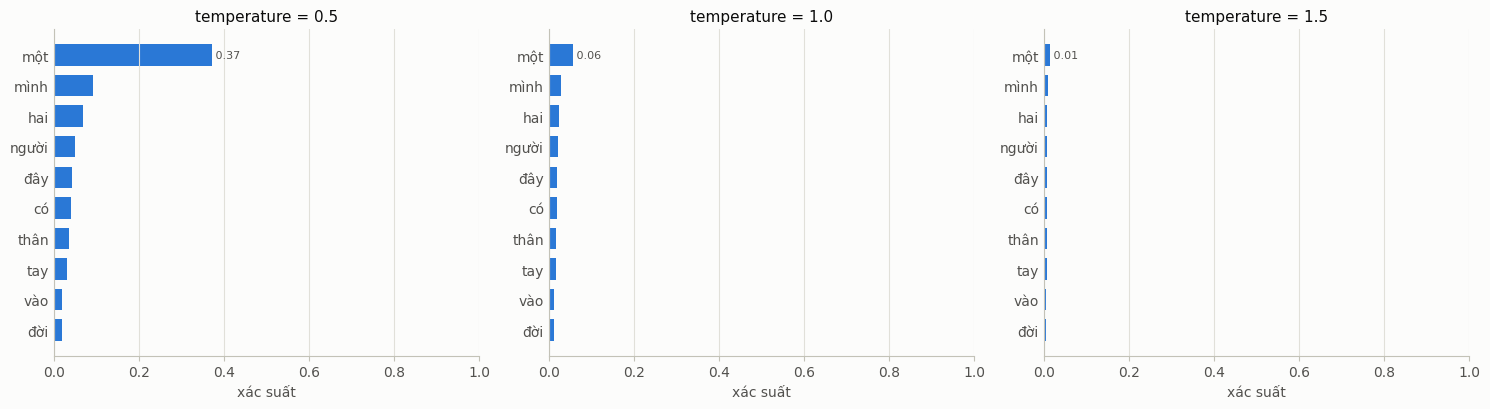

In [2]:
prompt = "Trăm năm trong cõi người ta,\nChữ tài chữ mệnh khéo là"
ids = torch.tensor([tokenizer.encode(prompt)], device=device)
with torch.no_grad():
    logits, _ = model(ids)
last_logits = logits[:, -1, :]  # (1, vocab_size): dự đoán cho vị trí sau "là"

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, temperature in zip(axes, [0.5, 1.0, 1.5]):
    probs = next_token_probs(last_logits, temperature)[0]
    top = torch.topk(probs, 10)
    viz.plot_token_probs(tokenizer.display_tokens(top.indices), top.values.cpu(), ax=ax, title=f"temperature = {temperature}")
plt.tight_layout()
plt.show()

**Top-k** giữ lại `k` token có điểm cao nhất, đặt xác suất của mọi token khác bằng 0 rồi chuẩn hóa lại. Nó cắt bỏ
"đuôi dài" hàng nghìn token hiếm – mỗi token chỉ có xác suất rất nhỏ, nhưng cộng lại thì không nhỏ chút nào:

In [3]:
probs = next_token_probs(last_logits, temperature=1.0)[0]
print(f"Tổng xác suất của 10 token mạnh nhất : {torch.topk(probs, 10).values.sum():.1%}")
print(f"Tổng xác suất của 3.990 token còn lại: {1 - torch.topk(probs, 10).values.sum():.1%}")
probs_top5 = next_token_probs(last_logits, temperature=1.0, top_k=5)[0]
print("Sau top-k = 5:", {tokenizer.id_to_piece(i): round(probs_top5[i].item(), 3) for i in torch.topk(probs_top5, 5).indices.tolist()})

Tổng xác suất của 10 token mạnh nhất : 23.3%
Tổng xác suất của 3.990 token còn lại: 76.7%
Sau top-k = 5: {'▁một': 0.381, '▁mình': 0.189, '▁hai': 0.163, '▁người': 0.139, '▁đây': 0.128}


## 2. Ảnh hưởng tới văn bản sinh ra

Cùng một câu mở đầu, cùng seed, chỉ đổi temperature (top-k tắt). `T = 0` là **greedy**: luôn chọn token có xác suất cao nhất.

In [4]:
prompt = "Trăm năm trong cõi người ta,"
for temperature in [0.0, 0.5, 1.0, 1.5]:
    print(f"=== temperature = {temperature} ===")
    print(generate_text(model, tokenizer, prompt, max_new_tokens=45, temperature=temperature, top_k=None, seed=1), "\n")

=== temperature = 0.0 ===
Trăm năm trong cõi người ta,
Một nhà đã thấy một mình ra.
Một mình lại một ngày một mình.
Một mình nàng mới là một mình.
Một mình nàng mới là một mình.
Một mình nàng mới là một mình, 

=== temperature = 0.5 ===
Trăm năm trong cõi người ta,
Nàng rằng: Thôi thì thôi lại là tình.
Một điều vàng chẳng đậu những người.
Trong quân một lời nói chẳng tiện,
Nàng từ nhà cũng phải bài,
Rằng: " ràng có một thân 

=== temperature = 1.0 ===


Trăm năm trong cõi người ta,
Dọn Châu đành gần mệnh bạc mệnh con!
Trước phải điều cho thiện, nhặt minh
Dặm rậm đề ơn nhờ thưa.
Sinh đà hỏi Tam đập ngọn mây bài,
Ầm xanh ân tri thù mặt lẩm 

=== temperature = 1.5 ===
Trăm năm trong cõi người ta,
Dọn Châu đành gần mệnh ngủi cất vành! gần thế thì chi cho thiện, nhặt minh nét thấp rậmoay ơn nhờ thưa thanhBú quân. hỏi Tam đập ngọn đứng bài,
Ầm xanh sôi?
Sự lẩm 



* `T = 0` (greedy) nhanh chóng rơi vào **vòng lặp**: cùng một câu lặp đi lặp lại – lỗi kinh điển của greedy decoding,
  vì cứ chọn token "an toàn nhất" thì dễ quay lại đúng chuỗi vừa viết.
* `T = 0.5`: câu ổn định, có dáng lục bát, nhưng dùng nhiều chữ phổ biến.
* `T = 1.0`: đa dạng hơn, nhiều chữ hiếm hơn, ít mạch lạc hơn.
* `T = 1.5`: phân phối quá phẳng, xuất hiện cả những "chữ" không có thật (các mảnh âm tiết bị ghép bừa) và câu không còn
  xuống dòng đúng nhịp.

Giờ cố định `T = 1.0` và đổi top-k:

In [5]:
for k in [1, 5, 50, None]:
    print(f"=== top_k = {k} ===")
    print(generate_text(model, tokenizer, prompt, max_new_tokens=45, temperature=1.0, top_k=k, seed=1), "\n")

=== top_k = 1 ===
Trăm năm trong cõi người ta,
Một nhà đã thấy một mình ra.
Một mình lại một ngày một mình.
Một mình nàng mới là một mình.
Một mình nàng mới là một mình.
Một mình nàng mới là một mình, 

=== top_k = 5 ===


Trăm năm trong cõi người ta,
Nàng đà biết đâu đã đến nơi.
Đã lòng có điều lòng có hai,
Một mình nàng ra sau lại một mình.
Đã lòng lại một ngày này?
Một nhà, đã thấy một mình, 

=== top_k = 50 ===


Trăm năm trong cõi người ta,
Người sao đành rồi cũng trong!
Giác Duyên đâu phải điều gần nào,
Cũng cho một ngày vào trời lại thưa.
Sinh đà tính thế này những thân.
Thấy chàng mới công cầu,
Sinh 

=== top_k = None ===
Trăm năm trong cõi người ta,
Dọn Châu đành gần mệnh bạc mệnh con!
Trước phải điều cho thiện, nhặt minh
Dặm rậm đề ơn nhờ thưa.
Sinh đà hỏi Tam đập ngọn mây bài,
Ầm xanh ân tri thù mặt lẩm 



Đo cho khách quan hơn: với mỗi temperature, sinh 10 đoạn rồi tính (1) tỉ lệ cụm 4 âm tiết **chép nguyên văn** từ
Truyện Kiều và (2) tỉ lệ cặp âm tiết liền nhau **không lặp lại** trong đoạn (càng cao càng đa dạng):

In [6]:
def syllables(text):
    return [w.strip(".,!?:;\"'").lower() for w in text.split() if w.strip(".,!?:;\"'")]


def ngrams(words, n):
    return [tuple(words[i : i + n]) for i in range(len(words) - n + 1)]


kieu_4grams = set(ngrams(syllables(load_corpus()), 4))
print(f"{'temperature':>12}{'chép nguyên văn':>18}{'cặp không lặp':>16}")
for temperature in [0.3, 0.6, 0.8, 1.0, 1.3]:
    copied, distinct = [], []
    for seed in range(10):
        words = syllables(generate_text(model, tokenizer, "", max_new_tokens=80, temperature=temperature, top_k=None, seed=seed))
        grams4, grams2 = ngrams(words, 4), ngrams(words, 2)
        copied.append(sum(g in kieu_4grams for g in grams4) / max(1, len(grams4)))
        distinct.append(len(set(grams2)) / max(1, len(grams2)))
    print(f"{temperature:>12}{sum(copied) / len(copied):>18.1%}{sum(distinct) / len(distinct):>16.1%}")

 temperature   chép nguyên văn   cặp không lặp


         0.3              2.7%           73.6%


         0.6              0.5%           95.7%


         0.8              0.2%           99.0%


         1.0              0.0%           99.8%


         1.3              0.0%          100.0%


Với top-k: `top_k = 1` chính là greedy (cùng vòng lặp); `top_k = 5` vẫn lặp khá nhiều; `top_k = 50` cắt bỏ đuôi dài
nên gọn gàng hơn hẳn bản không có top-k ở cùng temperature.

Bảng số liệu xác nhận điều ta thấy bằng mắt: temperature càng thấp, mô hình càng lặp lại (ở `T = 0.3` chỉ khoảng 3/4
số cặp chữ là không lặp) và càng hay chép nguyên văn Truyện Kiều; temperature càng cao, văn bản càng đa dạng nhưng
càng ít nghĩa. Không có giá trị "đúng" – đây là sự đánh đổi giữa an toàn và sáng tạo. Notebook 07 dùng
`temperature = 0.8, top_k = 50`.

## 3. Attention trên một cặp câu lục bát

Đưa hai câu thơ đầu qua mô hình rồi lấy trọng số attention đã lưu (`model.attention_maps()`): mỗi layer cho một tensor
`(B, n_head, T, T)`. Lưới dưới đây có một hàng cho mỗi layer, một cột cho mỗi head; trong mỗi ô, hàng là token đang
xét (query), cột là token được nhìn tới (key).

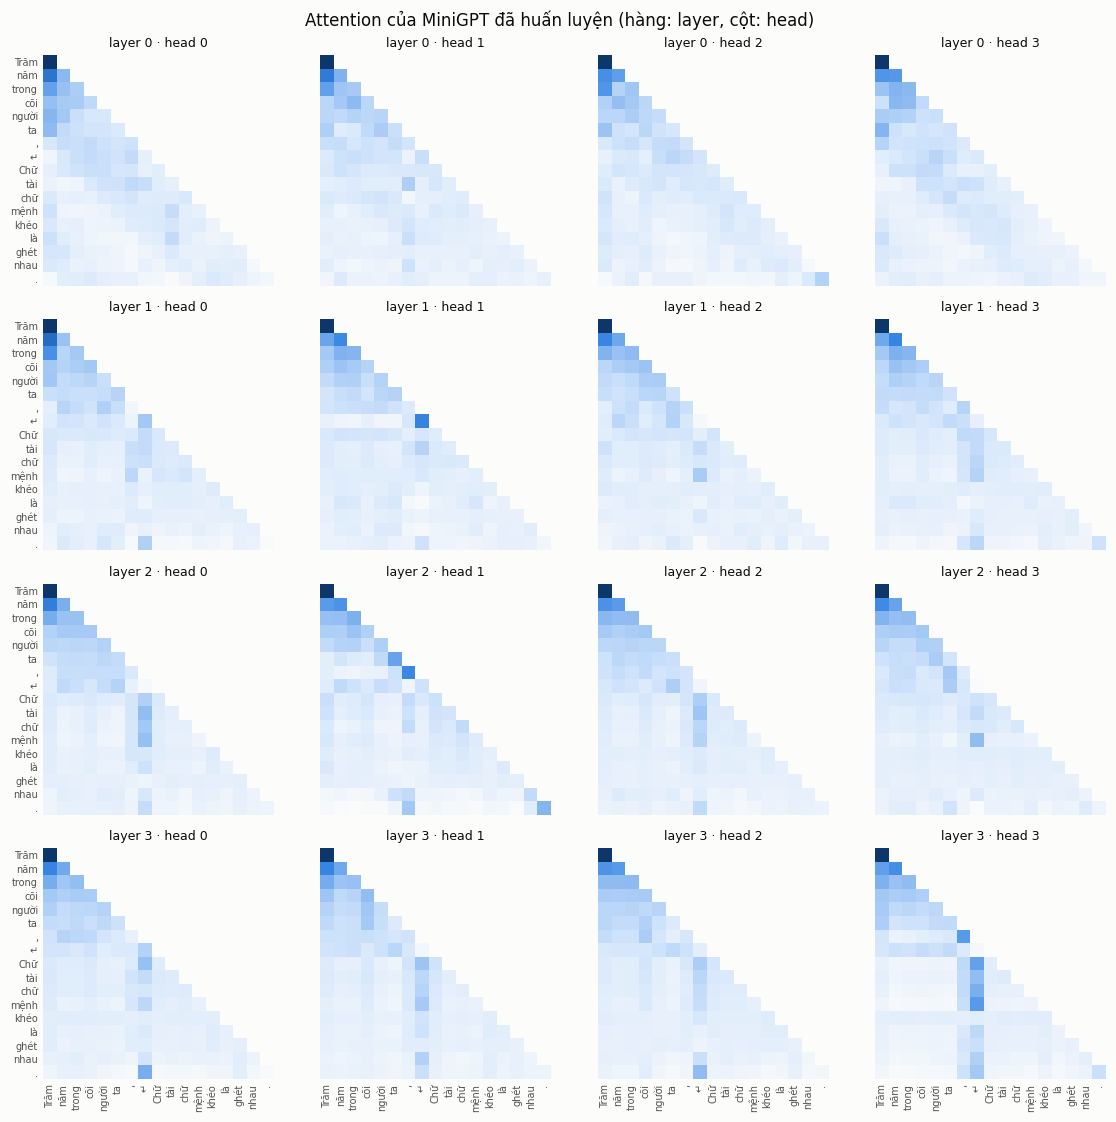

In [7]:
couplet = "Trăm năm trong cõi người ta,\nChữ tài chữ mệnh khéo là ghét nhau."
ids = torch.tensor([tokenizer.encode(couplet)], device=device)
with torch.no_grad():
    model(ids)
maps = [m[0].cpu() for m in model.attention_maps()]  # n_layer phần tử, mỗi phần tử (n_head, T, T)
labels = tokenizer.display_tokens(ids[0])
viz.plot_attention_grid(maps, labels, title="Attention của MiniGPT đã huấn luyện (hàng: layer, cột: head)")
plt.show()

Vài điều thấy ngay trên hình:

* Mấy hàng đầu đậm màu ở cột "Trăm" ở hầu hết các head. Phần lớn là do vị trí: hàng 0 chỉ nhìn được chính nó (luôn
  bằng 1), hàng 1 chỉ có 2 lựa chọn... nên các token đầu tự nhiên nhận nhiều trọng số.
* Ở layer 2 và 3, nhiều head cho các chữ của câu thứ hai ("Chữ", "tài", "chữ", "mệnh"...) nhìn mạnh vào dấu `↵` – ranh
  giới giữa hai câu thơ.

Nhưng một câu ví dụ chưa đủ để kết luận. Mục sau đo trên cả tập val.

## 4. Mỗi head làm việc gì? Đo trên cả tập val

Nhìn một câu thì dễ "thấy" những gì mình muốn thấy, nên ta đo trên mọi đoạn 64 token của tập val. Cần một mốc so sánh:
token ở vị trí `t` nhìn được `t + 1` token, nên nếu chia **đều** thì mỗi token nhận `1 / (t + 1)`. Với mỗi kiểu quan hệ,
ta đo xem head dồn vào các token "mục tiêu" **gấp bao nhiêu lần** mức chia đều đó: `1` = không ưu tiên (màu xám),
`> 1` = ưu tiên (xanh), `< 1` = né tránh (đỏ). Bốn kiểu quan hệ:

* **chữ ngay trước:** mục tiêu là token `t − 1`;
* **chính nó:** token `t`;
* **token đầu đoạn:** token ở vị trí 0 (nhiều mô hình lớn hay "đổ" attention thừa vào đây);
* **các dấu xuống dòng:** mọi token `<n>` đứng trước – tức ranh giới giữa các câu thơ.

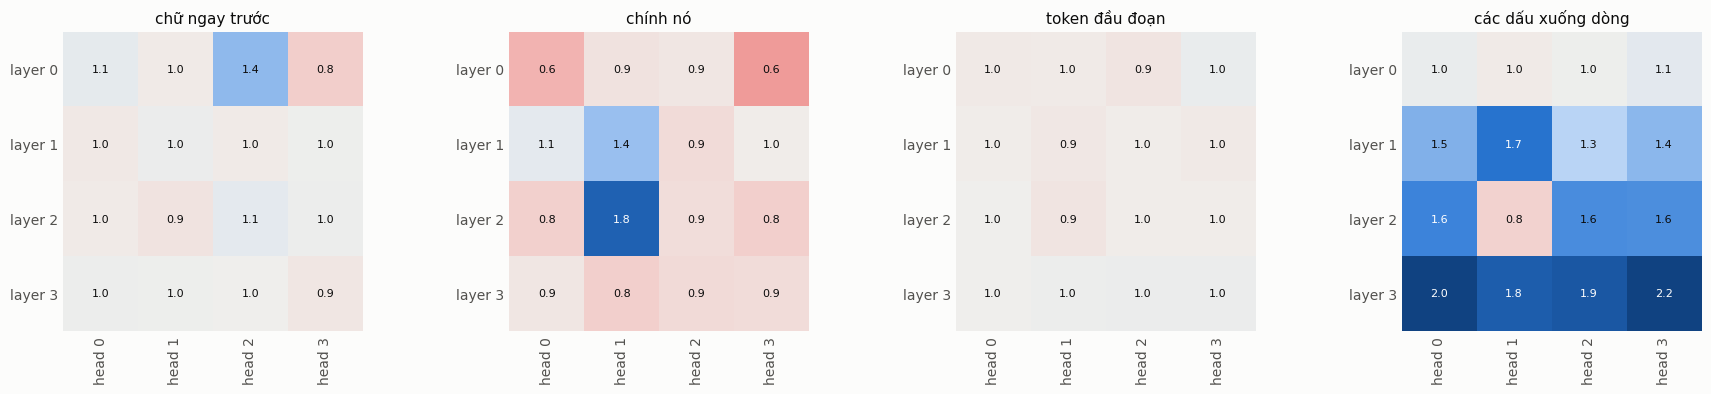

In [8]:
_, val_data = split_train_val(encode_corpus(tokenizer))
T = model.config.block_size
windows = val_data[: len(val_data) // T * T].view(-1, T)  # (N, T): các đoạn 64 token không chồng nhau
with torch.no_grad():
    model(windows.to(device))
attn = torch.stack(model.attention_maps(), dim=1).cpu()  # (N, n_layer, n_head, T, T)
N = windows.shape[0]
pos = torch.arange(T)
uniform = 1.0 / (pos + 1)  # (T,): trọng số mỗi token nhận được nếu query ở vị trí t chia đều


def lift(targets):
    """targets (N, T, T) kiểu bool – key nào là mục tiêu của query nào.
    Trả về (n_layer, n_head): attention dồn vào mục tiêu gấp bao nhiêu lần mức chia đều (trung bình mọi query)."""
    mass = (attn * targets[:, None, None]).sum(dim=-1)        # (N, n_layer, n_head, T)
    expected = targets.sum(dim=-1) * uniform                  # (N, T)
    has_target = targets.sum(dim=-1) > 0
    ratio = mass / expected.clamp_min(1e-9)[:, None, None]
    return (ratio * has_target[:, None, None]).sum(dim=(0, -1)) / has_target.sum()


prev_token = torch.zeros(T, T, dtype=torch.bool)
prev_token[pos[1:], pos[1:] - 1] = True
first_token = torch.zeros(T, T, dtype=torch.bool)
first_token[1:, 0] = True
before = torch.tril(torch.ones(T, T, dtype=torch.bool), diagonal=-1)  # key đứng trước query
newlines = (windows == tokenizer.newline_id)[:, None, :] & before     # mọi <n> đứng trước query

lifts = {
    "chữ ngay trước": lift(prev_token.expand(N, T, T)),
    "chính nó": lift(torch.eye(T, dtype=torch.bool).expand(N, T, T)),
    "token đầu đoạn": lift(first_token.expand(N, T, T)),
    "các dấu xuống dòng": lift(newlines),
}
heads = [f"head {h}" for h in range(model.config.n_head)]
layers = [f"layer {l}" for l in range(model.config.n_layer)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, s) in zip(axes, lifts.items()):
    viz.plot_matrix(s, ax=ax, xlabels=heads, ylabels=layers, cmap=viz.DIVERGING, vmin=0, vmax=2,
                    annotate=True, fmt=".1f", colorbar=False, aspect="equal", title=name)
plt.tight_layout()
plt.show()

* **Các dấu xuống dòng** là quan hệ nổi bật nhất: 11/12 head ở layer 1–3 dồn vào các `<n>` phía trước nhiều hơn mức
  chia đều, mạnh nhất ở layer 3 (khoảng 2 lần). Rất hợp lý: muốn biết nên viết tiếp hay xuống dòng, câu đang viết là câu
  6 hay 8 chữ, mô hình cần biết câu thơ hiện tại bắt đầu từ đâu.
* **Chính nó:** một head ở layer 2 tự nhìn mình nhiều gần gấp đôi mức chia đều.
* **Chữ ngay trước:** chỉ một head ở layer 0 hơi ưu tiên. Ở các mô hình lớn, kiểu head này thường rất rõ; mô hình nhỏ,
  học ít của ta chưa hình thành nó.
* **Token đầu đoạn:** không head nào ưu tiên (đều ≈ 1). Phần "đậm màu ở cột đầu" trên hình mục 3 chỉ là do các token
  đầu có ít lựa chọn.

### Head chú ý tới dấu xuống dòng rõ nhất

Xem head đó làm việc trên bốn câu thơ (hai cặp lục bát):

layer 3, head 3: nhìn các dấu xuống dòng gấp 2.2 lần mức chia đều


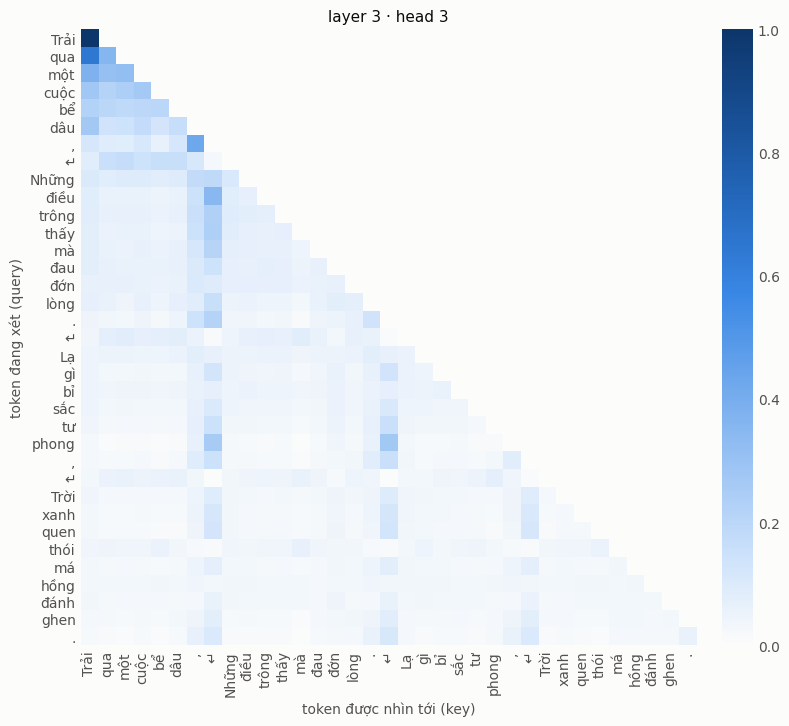

In [9]:
newline_lift = lifts["các dấu xuống dòng"]
layer, head = divmod(int(newline_lift.argmax()), model.config.n_head)
print(f"layer {layer}, head {head}: nhìn các dấu xuống dòng gấp {newline_lift[layer, head]:.1f} lần mức chia đều")

passage = "\n".join(load_corpus().split("\n")[2:6])
passage_ids = torch.tensor([tokenizer.encode(passage)], device=device)
with torch.no_grad():
    model(passage_ids)
viz.plot_attention(model.attention_maps()[layer][0, head].cpu(), tokenizer.display_tokens(passage_ids[0]),
                   title=f"layer {layer} · head {head}")
plt.show()

## 5. Có head nào "bắt vần" lục bát không?

Luật vần cơ bản của lục bát: **chữ thứ 6 của câu bát (8 chữ) vần với chữ thứ 6 – chữ cuối – của câu lục (6 chữ) ngay
trên**. Ví dụ: "Trăm năm trong cõi người **ta**, / Chữ tài chữ mệnh khéo **là** ghét nhau."

Mô hình causal đoán chữ thứ 6 khi đang đứng ở **chữ thứ 5** của câu bát. Nếu có một head chuyên lo chuyện vần, khi ở
vị trí đó nó nên nhìn về chữ cuối câu lục. Ta đo trọng số attention từ chữ thứ 5 câu bát tới chữ thứ 6 câu lục, so với
trọng số trung bình tới 5 chữ còn lại của câu lục (mức "nền"), trên mọi cặp câu đúng 6–8 chữ của Truyện Kiều:

Số cặp câu dùng để đo: 1620


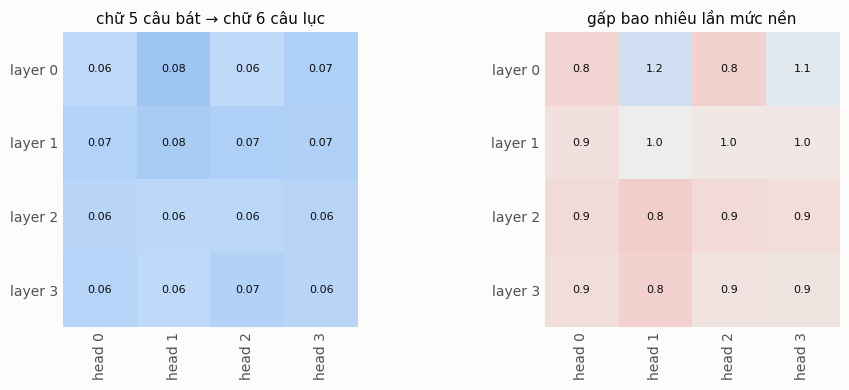

In [10]:
lines = load_corpus().split("\n")


def syllable_positions(token_ids):
    """Vị trí các token là đầu một âm tiết (bắt đầu bằng ▁ và có chữ cái)."""
    pieces = [tokenizer.id_to_piece(i) for i in token_ids]
    return [p for p, piece in enumerate(pieces) if piece.startswith("▁") and any(c.isalpha() for c in piece)]


rhyme = torch.zeros(model.config.n_layer, model.config.n_head)
baseline = torch.zeros_like(rhyme)
n_couplets = 0
for luc, bat in zip(lines[0::2], lines[1::2]):
    token_ids = tokenizer.encode(luc + "\n" + bat)
    syl = syllable_positions(token_ids)
    if len(syl) != 14 or len(token_ids) > model.config.block_size:  # chỉ lấy cặp đúng 6 + 8 chữ
        continue
    luc_syl, bat_syl = syl[:6], syl[6:]
    with torch.no_grad():
        model(torch.tensor([token_ids], device=device))
    a = torch.stack(model.attention_maps(), dim=1)[0].cpu()  # (n_layer, n_head, T, T)
    query = bat_syl[4]                                        # chữ thứ 5 của câu bát
    rhyme += a[:, :, query, luc_syl[5]]                       # -> chữ thứ 6 của câu lục
    baseline += a[:, :, query, luc_syl[:5]].mean(dim=-1)      # -> 5 chữ còn lại của câu lục
    n_couplets += 1

rhyme, baseline = rhyme / n_couplets, baseline / n_couplets
print(f"Số cặp câu dùng để đo: {n_couplets}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
viz.plot_matrix(rhyme, ax=axes[0], xlabels=heads, ylabels=layers, vmin=0, vmax=max(0.3, float(rhyme.max())),
                annotate=True, colorbar=False, aspect="equal", title="chữ 5 câu bát → chữ 6 câu lục")
viz.plot_matrix(rhyme / baseline, ax=axes[1], xlabels=heads, ylabels=layers, cmap=viz.DIVERGING, vmin=0, vmax=2,
                annotate=True, fmt=".1f", colorbar=False, aspect="equal", title="gấp bao nhiêu lần mức nền")
plt.tight_layout()
plt.show()

Câu trả lời trung thực: **không**. Mọi head đều nhìn chữ thứ 6 của câu lục ở quanh mức nền (tỉ lệ khoảng 0,8–1,2). Mô
hình đã học được *nhịp dòng thơ* (mục 4) nhưng chưa học được *luật vần*. Điều này dễ hiểu: để bắt vần, mô hình phải
biết hai âm tiết nào vần với nhau (cùng phần vần, cùng thanh bằng) – một kiến thức về *âm thanh* mà nó chỉ có thể suy
ra gián tiếp từ khoảng 1.600 cặp câu, và mỗi âm tiết lại chỉ là một token id không mang thông tin chính tả.

Đây cũng là cách làm của nghiên cứu khả năng diễn giải (*interpretability*): đặt giả thuyết cụ thể, đo, và chấp nhận cả
kết quả âm tính. Muốn mô hình học được vần, có thể thử: thêm nhiều thơ lục bát hơn, mô hình lớn hơn, hoặc tokenizer tách
riêng phụ âm đầu và phần vần.

## 6. Embedding sau khi huấn luyện

### Positional embedding đã học

Ở notebook 03, bảng vị trí lúc khởi tạo chỉ là nhiễu. Sau khi học, độ tương đồng cosine giữa các vị trí cho thấy cấu trúc:

Độ dài trung bình một câu thơ: 9.1 token (kể cả dấu câu và <n>)


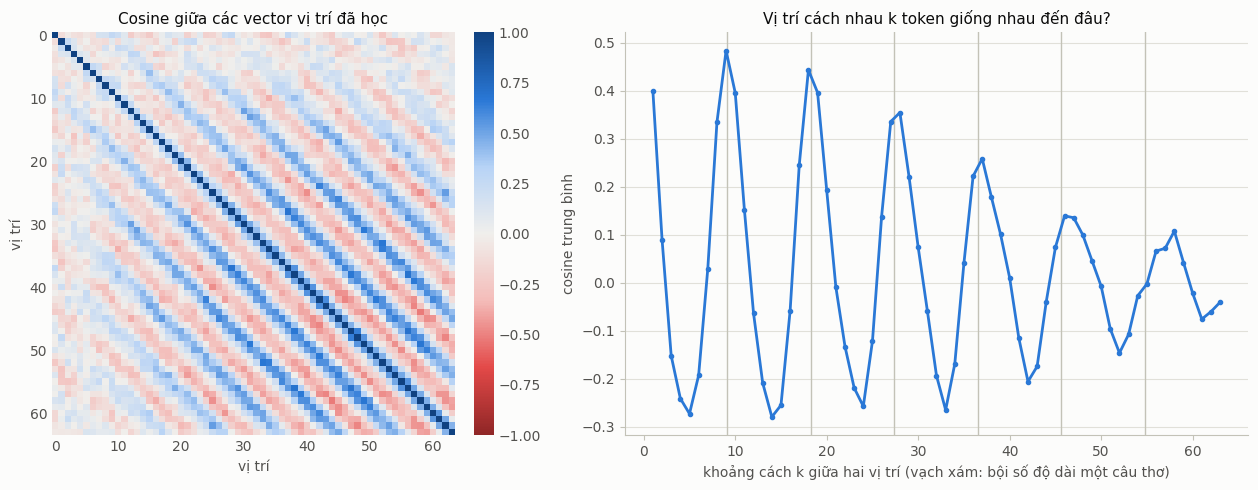

In [11]:
if isinstance(model.pos_emb, LearnedPositionalEmbedding):
    P = model.pos_emb.table.weight.detach().cpu()
    unit = P / P.norm(dim=1, keepdim=True)
    similarity = unit @ unit.T                                                  # (T, T)
    by_offset = [similarity.diagonal(k).mean().item() for k in range(1, T)]     # cosine trung bình theo khoảng cách k
    tokens_per_line = len(encode_corpus(tokenizer)) / len(load_corpus().split("\n"))
    print(f"Độ dài trung bình một câu thơ: {tokens_per_line:.1f} token (kể cả dấu câu và <n>)")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    viz.plot_matrix(similarity, ax=axes[0], cmap=viz.DIVERGING, vmin=-1, vmax=1, aspect="equal",
                    title="Cosine giữa các vector vị trí đã học", xlabel="vị trí", ylabel="vị trí")
    for m in range(1, 7):
        axes[1].axvline(m * tokens_per_line, color=viz.AXIS, linewidth=1)
    axes[1].plot(range(1, T), by_offset, color=viz.COLORS[0], marker="o", markersize=3)
    axes[1].set(xlabel="khoảng cách k giữa hai vị trí (vạch xám: bội số độ dài một câu thơ)",
                ylabel="cosine trung bình", title="Vị trí cách nhau k token giống nhau đến đâu?")
    axes[1].grid(axis="y")
    plt.tight_layout()
    plt.show()
else:
    print("Mô hình dùng sinusoidal encoding (cố định) – xem notebook 03.")

Một phát hiện đẹp. Heatmap bên trái có các sọc chéo song song; đồ thị bên phải cho thấy rõ hơn: hai vị trí cách nhau
khoảng 9, 18, 27... token có vector **giống nhau**, cách nhau khoảng 4–5 token thì **ngược hướng**. Các đỉnh trùng với
vạch xám – bội số của độ dài trung bình một câu thơ (9,1 token).

Không ai dạy mô hình điều này. Nó tự phát hiện **nhịp của thơ lục bát** và cài vào vector vị trí, giống như tự học ra
một thành phần sin/cos (notebook 03) có chu kỳ bằng đúng độ dài câu thơ. Nhờ vậy attention có thể dễ dàng tìm "vị trí
tương ứng ở câu trước".

### Token embedding: láng giềng gần nhất

Lấy vector đầu vào của mọi token (sau lớp chiếu, nếu mô hình dùng fastText) rồi tìm các token gần nhất theo cosine:

In [12]:
with torch.no_grad():
    E = model.tok_emb(torch.arange(tokenizer.vocab_size, device=device)).cpu()  # (vocab_size, d_model)
E_unit = E / E.norm(dim=1, keepdim=True)
for word in ["nàng", "chàng", "hoa", "trăng", "buồn", "một"]:
    i = tokenizer.piece_to_id("▁" + word)
    sims = E_unit @ E_unit[i]
    best = [j for j in torch.argsort(sims, descending=True).tolist() if j != i][:6]
    print(f"{word:>6} → " + ", ".join(f"{tokenizer.id_to_piece(j).replace('▁', '')} ({sims[j]:.2f})" for j in best))

  nàng → bù (0.44), nàn (0.42), chàng (0.39), chầy (0.38), nghỉ (0.36), buổi (0.35)
 chàng → Ôi (0.40), nàn (0.39), hòng (0.39), nàng (0.39), giờ (0.36), Sinh (0.35)
   hoa → ỹ (0.36), oanh (0.31), tham (0.30), luân (0.28), điều (0.28), Giang (0.27)
 trăng → khiên (0.36), Đêm (0.34), phỏng (0.33), trải (0.32), phất (0.31), cữ (0.31)
  buồn → ngắt (0.35), kỹ (0.34), ngói (0.31), ào (0.30), Cát (0.29), Lần (0.28)
   một → Định (0.48), ban (0.45), ẩn (0.44), gò (0.44), sè (0.42), viễn (0.41)


Phần lớn láng giềng là nhiễu, chỉ lác đác vài cặp có nghĩa (`nàng` ↔ `chàng`). Giống mô hình bigram ở notebook 02,
embedding học từ khoảng 27 nghìn token chưa đủ để mang ngữ nghĩa rõ ràng; phần "hiểu" của mô hình nằm nhiều hơn ở các
khối Transformer. Đây cũng là lý do dùng vector fastText đóng băng lại giúp ích ở notebook 07.

## Tóm tắt

* Sinh văn bản = lặp lại "logits → (temperature, top-k) → xác suất → lấy mẫu một token → nối vào chuỗi".
* Temperature thấp: an toàn, lặp lại, chép nhiều; temperature cao: đa dạng nhưng nhanh chóng vô nghĩa. Top-k cắt bỏ
  đuôi dài các token hiếm.
* Muốn biết một head "làm gì", hãy **đo** trên nhiều dữ liệu và so với một mốc (ở đây: chia đều), đừng chỉ nhìn một câu.
* MiniGPT học được **cấu trúc dòng thơ**: các head ở layer sau ưu tiên nhìn về ranh giới câu thơ, và vector vị trí mang
  nhịp tuần hoàn bằng đúng độ dài trung bình một câu. Nhưng nó **chưa** học được vần lục bát.
* Đây vẫn là một mô hình rất nhỏ học trên 27 nghìn token: thơ sinh ra có dáng lục bát nhưng chưa mạch lạc về nghĩa.

Bạn đã đi hết luồng dữ liệu của một Transformer decoder-only: **văn bản → token → embedding + vị trí → N khối
Transformer → logits → token tiếp theo**. Xem mục "Bước tiếp theo" trong `README.md` để đi xa hơn.

---

## Bài tập

Đáp án: `solutions/08_generate_and_visualize.md`

**Bài 1.** Tự viết một câu mở đầu (ví dụ "Nàng rằng:" hoặc "Chàng về") và thử ít nhất 3 cấu hình `temperature`/`top_k`.
Cấu hình nào cho thơ "giống lục bát" nhất?

In [13]:
# TODO: generate_text(model, tokenizer, "Nàng rằng:", max_new_tokens=60, temperature=..., top_k=..., seed=0)

**Bài 2.** Cài **top-p (nucleus) sampling**: sắp xếp xác suất giảm dần, giữ nhóm token nhỏ nhất có tổng xác suất
≥ `p`, bỏ phần còn lại rồi chuẩn hóa. So sánh với top-k trên phân phối ở mục 1.

In [14]:
def top_p_probs(logits, p=0.9, temperature=1.0):
    """TODO: trả về xác suất (1, vocab_size) sau khi áp temperature và top-p."""
    return next_token_probs(logits, temperature)  # thay bằng cài đặt của bạn


print(int((top_p_probs(last_logits, p=0.9) > 0).sum()), "token còn lại sau top-p")

4000 token còn lại sau top-p


**Bài 3.** (a) Trong MiniGPT, kiểu chú ý rõ nhất là nhìn về các dấu xuống dòng. Vì sao thông tin này hữu ích cho việc
đoán token tiếp theo trong thơ lục bát? (b) Ở các mô hình lớn, head "nhìn chữ ngay trước" xuất hiện rất phổ biến. Nó
kết hợp với một head ở layer sau như thế nào để tạo thành cơ chế "sao chép" (gợi ý: tìm hiểu về *induction head*)?